## Visualtization Task

### Univariate

In [ ]:
# Importing libraries
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

conn = mysql.connector.connect(host="localhost", user="root",
                               password="Assasin#96", database="project_1")
cursor = conn.cursor()

def run_query(sql):
    cursor.execute(sql)
    return pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)

movies       = run_query("SELECT * FROM movies")
genres       = run_query("SELECT * FROM genres")
movie_genres = run_query("SELECT * FROM movie_genres")

movies["release_date"] = pd.to_datetime(movies["release_date"])
movies["release_year"] = movies["release_date"].dt.year
movies["decade"] = movies["release_year"] // 10 * 10

# Primary genre = first genre listed for each movie 
primary = movie_genres.drop_duplicates("movie_id").merge(genres, on="genre_id")
movies = movies.merge(primary[["movie_id", "genre_name"]].rename(columns={"genre_name": "primary_genre"}),
                      on="movie_id", how="left")

# for financial columns( revenue, budget) use only movies with BOTH values known (> 0)
financial = movies[(movies["budget"] > 0) & (movies["revenue"] > 0)].copy()
print(len(movies), "movies;", len(financial), "with known budget and revenue")

2503 movies; 2370 with known budget and revenue


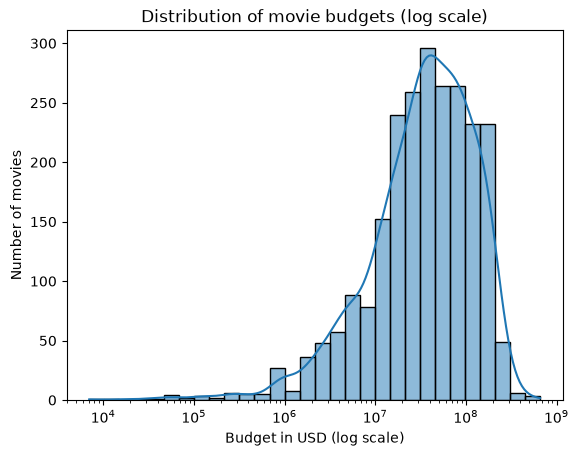

In [ ]:
# Budget Distribution
sns.histplot(financial["budget"], log_scale=True, kde=True, bins=30)   
plt.title("Distribution of movie budgets (log scale)")
plt.xlabel("Budget in USD (log scale)")
plt.ylabel("Number of movies")
plt.show()

* Budgets form a bell-curve (log scale). Most movies fall between approximately $10M and $200M and the peak at approximately $40M–$100M.

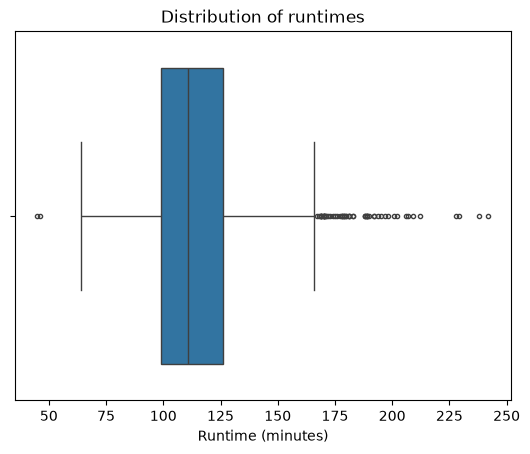

In [16]:
# Runtime distribution
# fig, ax = plt.subplots(figsize=(8, 2.8))
sns.boxplot(x=movies["runtime"],  fliersize=3)
plt.title("Distribution of runtimes")
plt.xlabel("Runtime (minutes)")
plt.show()

* Most movies are around 111 minutes long. The IQR ranges between approx 99-126 minutes. There is a long right tail. Many films (dozens) are longer than the whisker of 166 minutes, reaching up to approx 240 minutes. However there are only two short films (~45 mins)

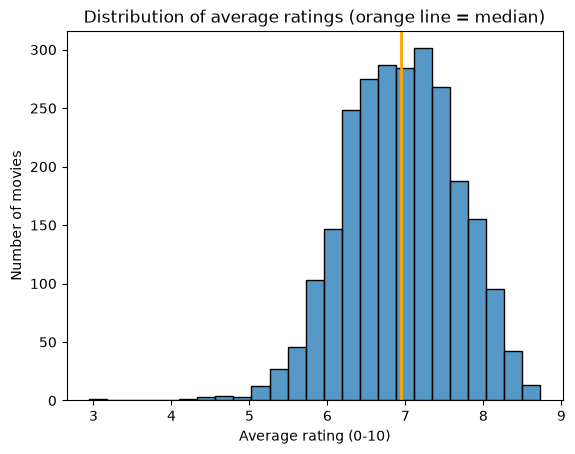

In [ ]:
# Rating Distribution
fig, ax = plt.subplots()
sns.histplot(movies["vote_average"], bins=25,  ax=ax)
ax.axvline(movies["vote_average"].median(), color = 'orange', linewidth=2)
ax.set_title("Distribution of average ratings (orange line = median)")
ax.set_xlabel("Average rating (0-10)"); ax.set_ylabel("Number of movies")
plt.show()


* The ratings form an approximate bell-curve with the median being ~6.95. Most films are between 6-8. 

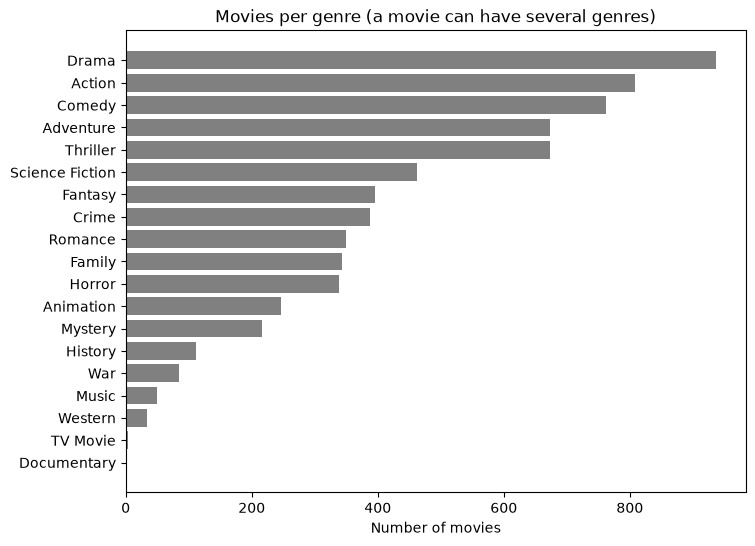

In [ ]:
genre_counts = movie_genres.merge(genres, on="genre_id")["genre_name"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(genre_counts.index, genre_counts.values, color='grey')
ax.set_title("Movies per genre (a movie can have several genres)")
ax.set_xlabel("Number of movies"); ax.grid(axis="y", visible=False)
plt.show()

* Drama is the most popular genre (~935 films) followed by Action (~805) and Comedy (~760). Documentaries and TV Movies are almost non-existent.*

## Bivariate

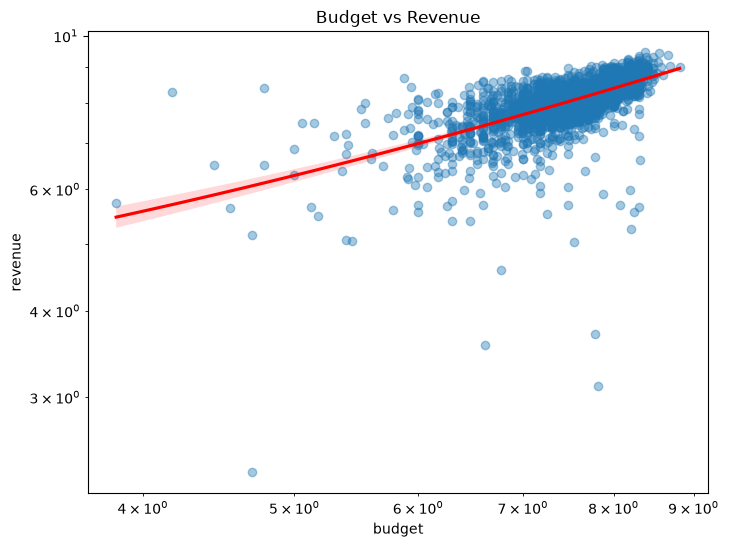

In [ ]:
# Budget vs revenue (scatter plot, with trend line)

plt.figure(figsize=(8, 6))

sns.regplot(
    x=np.log10(financial["budget"]),
    y=np.log10(financial["revenue"]),
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.xscale("log")
plt.yscale("log")
plt.title("Budget vs Revenue")
plt.show()

* There is a positive trend meaning films with higher budgets tend to gain higher revenues.

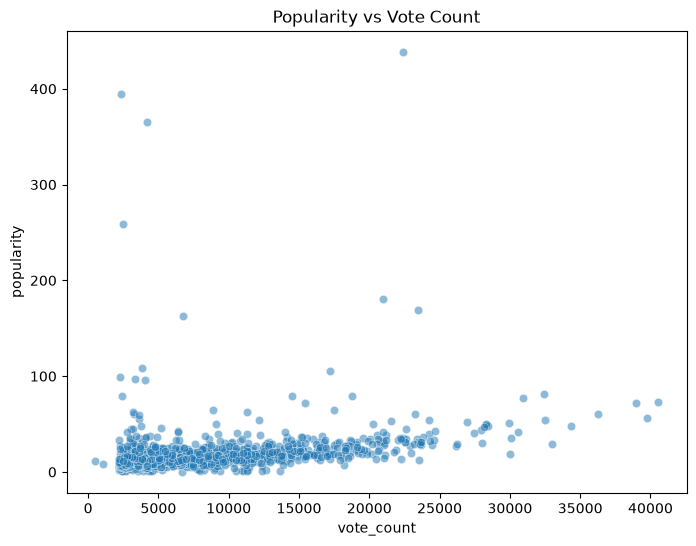

In [104]:
# Popularity vs vote count (scatter plot

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=movies,
    x="vote_count",
    y="popularity",
    alpha=0.5
)

plt.title("Popularity vs Vote Count")
plt.show()

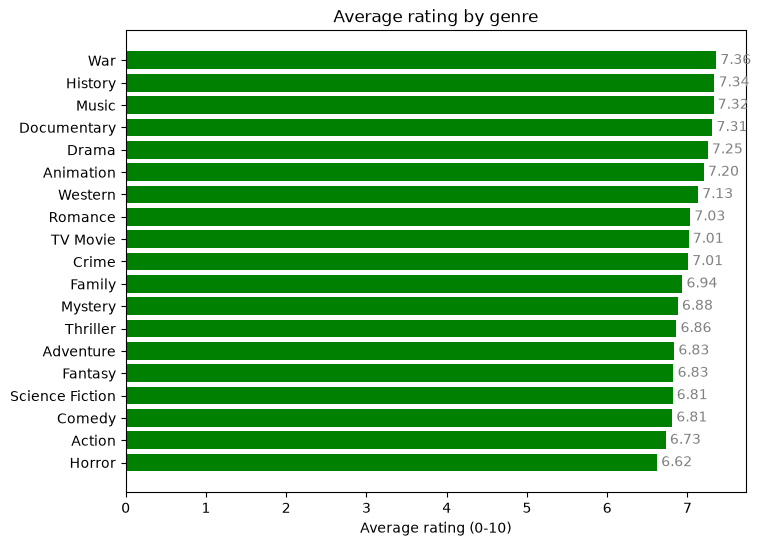

In [ ]:
# Average rating by genre (bar chart)
all_genres = movie_genres.merge(genres, on="genre_id").merge(movies[["movie_id", "vote_average"]], on="movie_id")
avg_rating = all_genres.groupby("genre_name")["vote_average"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(avg_rating.index, avg_rating.values, color='green')           
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, color='grey')
ax.set_title("Average rating by genre")
ax.set_xlabel("Average rating (0-10)"); ax.grid(axis="y", visible=False)
plt.show()

* War, History, Music and Drama had the highest average ratings (7.36, 7.34, 7.32 and 7.25 respectively). Horror and Action had the lowest (6.62 and 6.73). Overall the difference is less than 0.75 so genre doesn’t really affect ratings.

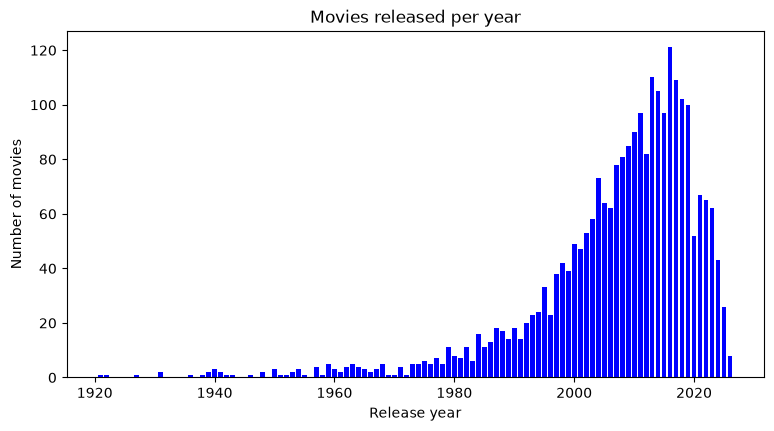

In [37]:
# Number of movies released per year (bar/column chart)

per_year = movies["release_year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(per_year.index, per_year.values, color='blue', width=0.8)
ax.set_title("Movies released per year")
ax.set_xlabel("Release year"); ax.set_ylabel("Number of movies")
plt.show()

* Before 1980 there are very few films each year. There is a sharp increase throughout the 1990s and 2000s. In 2016 there were ~120 films.

### Multivariate

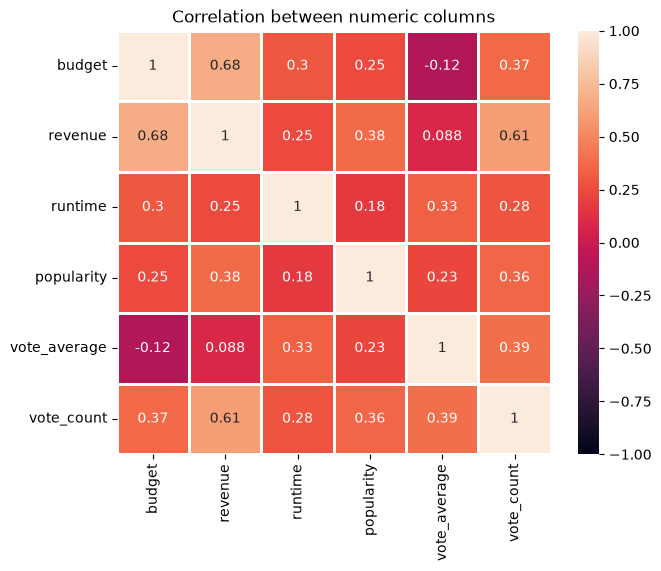

In [ ]:
# Correlation heatmap of budget, revenue, runtime, popularity, vote_average and vote_count (heatmap).

cols = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]
corr = financial[cols].corr()                   

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True,  vmin=-1, vmax=1, linewidths=2, linecolor="white", ax=ax)
ax.set_title("Correlation between numeric columns")
plt.show()

* Budget and Revenue are highly correlated (0.68). Revenue and Votes are also highly correlated (0.61). This means high budget films have higher revenues

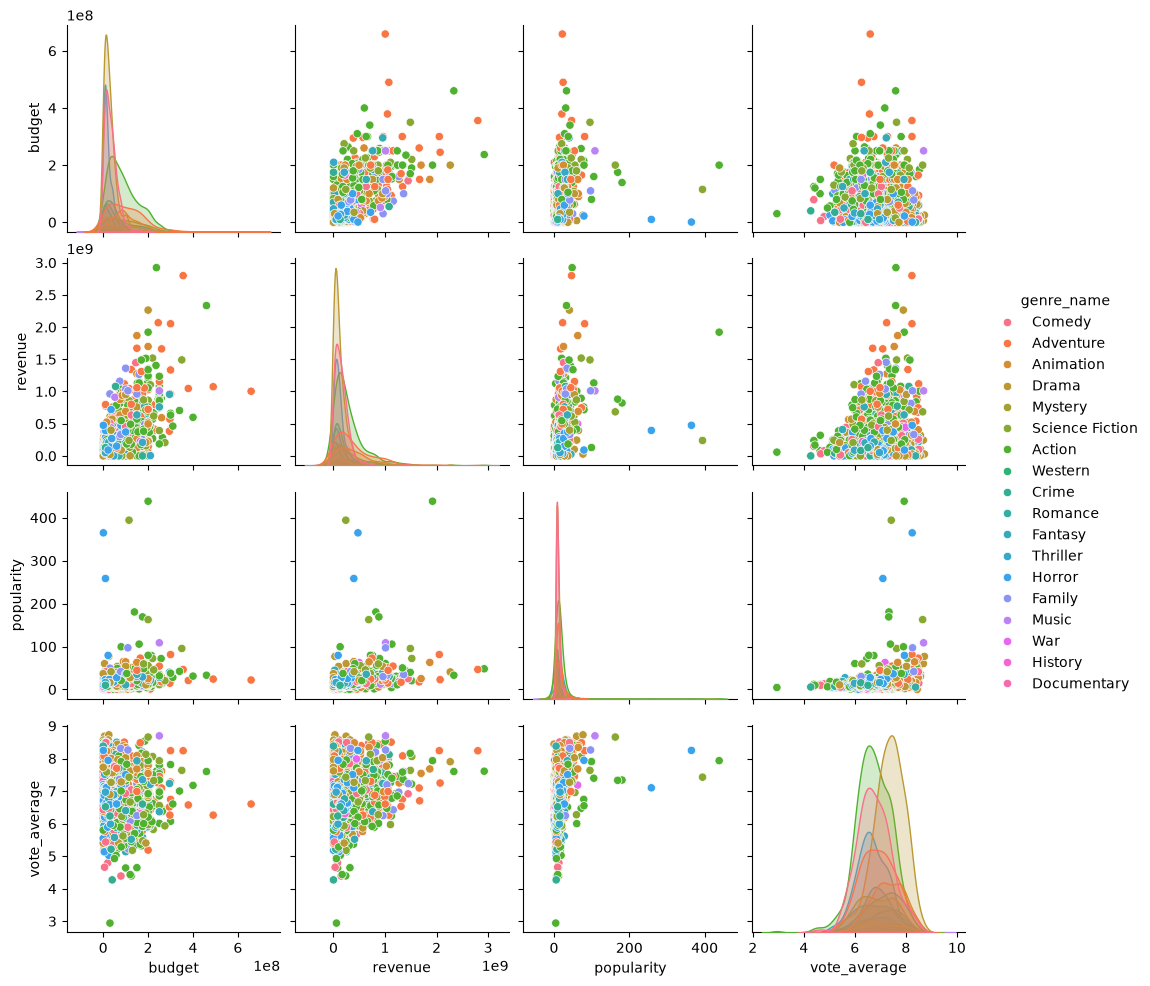

In [71]:
# Pairplot of budget, revenue, popularity and vote_average, colored by primary genre (pairplot).
pairplot_df= movies.merge(primary[['movie_id','genre_name']], on='movie_id')

sns.pairplot(pairplot_df, vars=['budget', 'revenue', 'popularity', 'vote_average'], hue = 'genre_name')


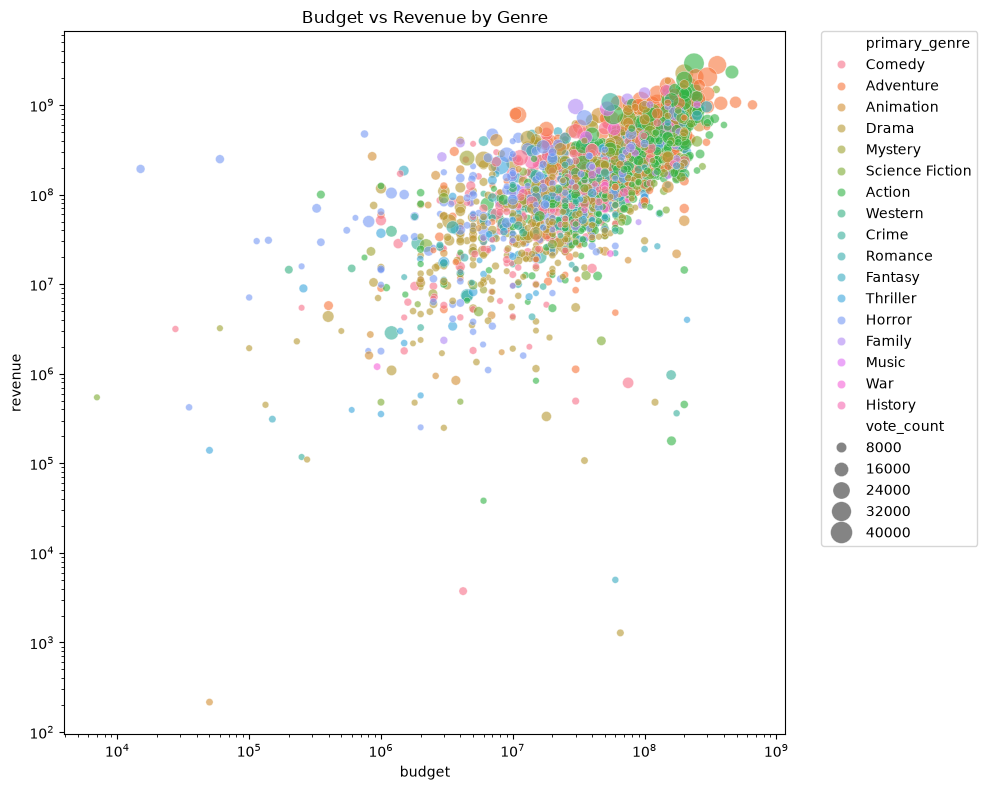

In [99]:
# Budget vs revenue colored by primary genre, with point size showing vote_count (scatter plot with hue and size).
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=financial,
    x="budget",
    y="revenue",
    hue="primary_genre",
    size="vote_count",
    sizes=(10, 250),
    alpha=0.6
)

plt.xscale("log")
plt.yscale("log")
plt.title("Budget vs Revenue by Genre")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    borderaxespad=0
)

plt.tight_layout()
plt.show()

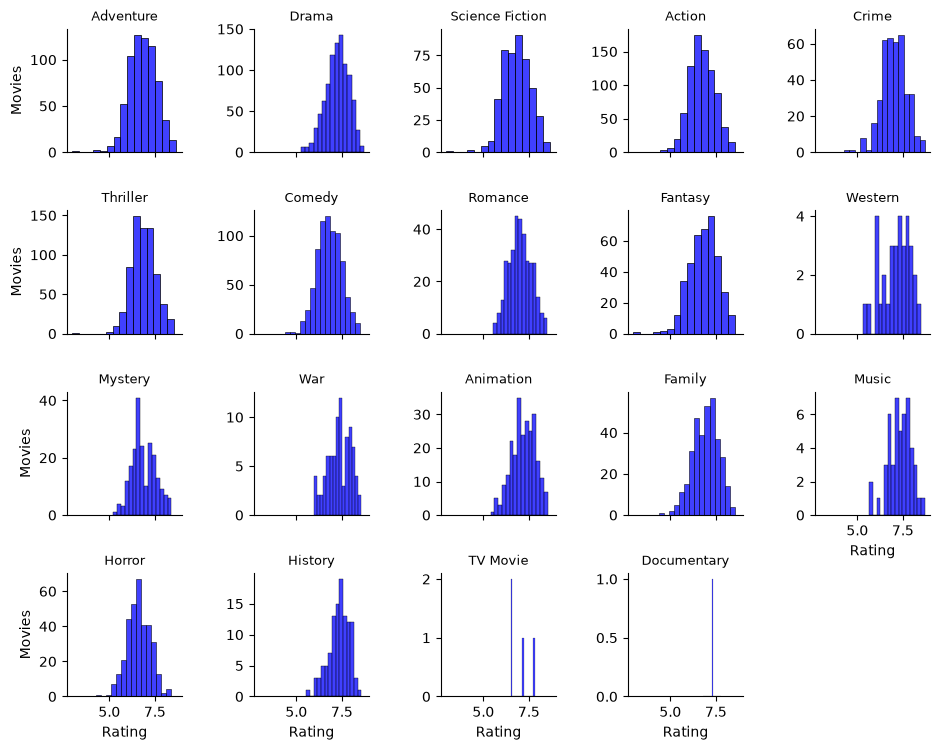

In [ ]:
# Distribution of vote_average for each genre in separate panels (FacetGrid with histograms).
facet_data = movie_genres.merge(genres, on="genre_id").merge(movies[["movie_id", "vote_average"]], on="movie_id")

g = sns.FacetGrid(facet_data, col="genre_name", col_wrap=5, height=1.9)
g.map_dataframe(sns.histplot, x="vote_average", bins=15, color='blue')
g.set_titles("{col_name}", size=9)
g.set_axis_labels("Rating", "Movies")
plt.show()

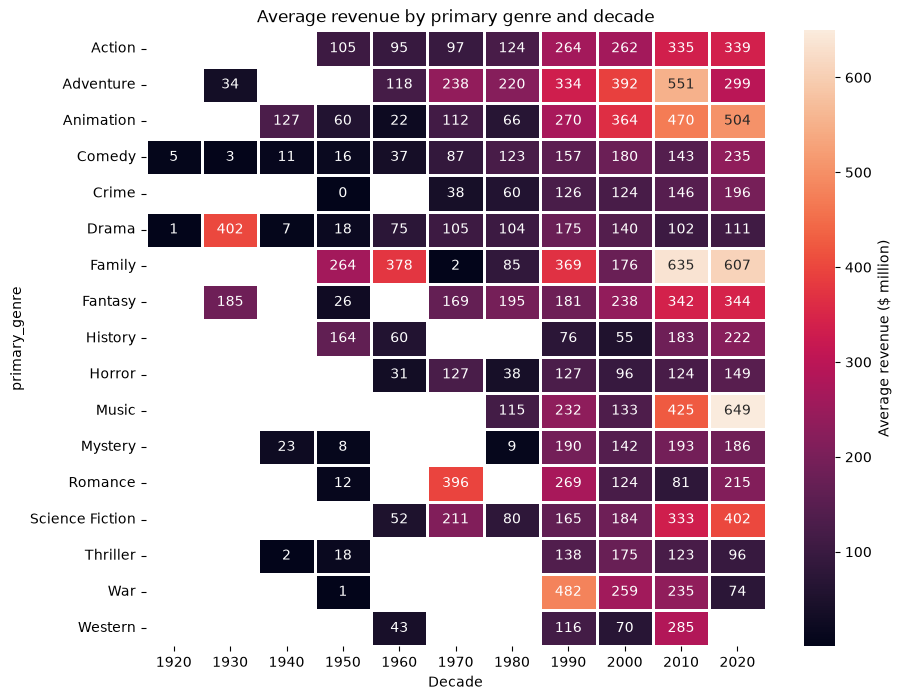

In [95]:
# Average revenue by genre and release decade (heatmap of a pivot table).

cells = financial.groupby(["primary_genre", "decade"])["revenue"].agg(["mean", "count"]).reset_index()
pivot = cells.pivot(index="primary_genre", columns="decade", values="mean") / 1e6      

plt.figure(figsize=(10, 8))
sns.heatmap(pivot, annot=True, fmt=".0f",  linewidths=2, linecolor="white",
            cbar_kws={"label": "Average revenue ($ million)"})
plt.title("Average revenue by primary genre and decade")
plt.xlabel("Decade"); ax.set_ylabel("")
plt.show()

* Nearly all genres have seen a sharp increase in average revenue since the 1990s. Action went from $105M in the 1950s to $339M in the 2020s. The highest recent averages are Music ($649M, 2020s), Family ($635M in the 2010s) and ($607M, 2020s), Adventure ($551M in the 2010s). Animation also had a high average of $504M, 2020s), while Drama stays at about $100-175M.